# Import Libs

In [1]:
from pathlib import Path

import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


# Project directories

In [2]:
PROJECT_DIR = Path.cwd()

# Support running the notebook from the project root
if not (PROJECT_DIR / "requirements.txt").exists():
    PROJECT_DIR = PROJECT_DIR.parent

IMAGES_DIR = PROJECT_DIR / "docs" / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("ggplot")

print("Project directory:", PROJECT_DIR)
print("Images directory:", IMAGES_DIR)

Project directory: c:\Users\Rafael\Documents\Projects\Personal\Data\b3-analytics
Images directory: c:\Users\Rafael\Documents\Projects\Personal\Data\b3-analytics\docs\images


# Load .xlsx Data

In [7]:

# Locate the project directory
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "requirements.txt").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Path to the Excel file generated by main.py
file_path = PROJECT_DIR / "data" / "petr4_hist.xlsx"

if not file_path.exists():
    raise FileNotFoundError(
        f"Excel file not found: {file_path}. "
        "Run main.py first to generate the file."
    )

# Load historical data from Excel
df = pd.read_excel(
    file_path,
    index_col=0,
    parse_dates=True
)

# Standardize column names
df.columns = df.columns.str.strip()

# Check whether the expected columns exist
required_columns = ["Close", "Volume"]
missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in Excel file: {missing_columns}. "
        f"Available columns: {list(df.columns)}"
    )

# Keep only the columns needed for this analysis
df = df[["Close", "Volume"]].copy()

# Ensure numeric values and remove missing closing prices
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df["Volume"] = pd.to_numeric(df["Volume"], errors="coerce")
df = df.dropna(subset=["Close"])

# Sort by date
df = df.sort_index()

display(df.head())
print(f"\nNumber of observations: {len(df)}")
print(f"Period: {df.index.min().date()} to {df.index.max().date()}")


,Close,Volume
Date,,
2025-10-28,27.335201,25324800
2025-10-29,27.362545,24854900
2025-10-30,27.244051,22657200
2025-10-31,27.116446,29516300
2025-11-03,27.435465,54977300



Number of observations: 249
Period: 2025-10-28 to 2026-10-28


\[
R_t = \frac{P_t}{P_{t-1}} - 1
\]

In [9]:
# Daily percentage return
df["Daily_Return"] = df["Close"].pct_change()

# Cumulative return since the first observation
df["Cumulative_Return"] = (
    (1 + df["Daily_Return"].fillna(0)).cumprod() - 1
)

display(df.tail())

,Close,Volume,Daily_Return,Cumulative_Return
Date,,,,
2026-10-22,57.830002,39860200,0.001385,1.115587
2026-10-23,58.680000,58347500,0.014698,1.146683
2026-10-26,53.880001,141338400,-0.081800,0.971085
2026-10-27,52.790001,80592800,-0.020230,0.931210
2026-10-28,52.509998,54841600,-0.005304,0.920966


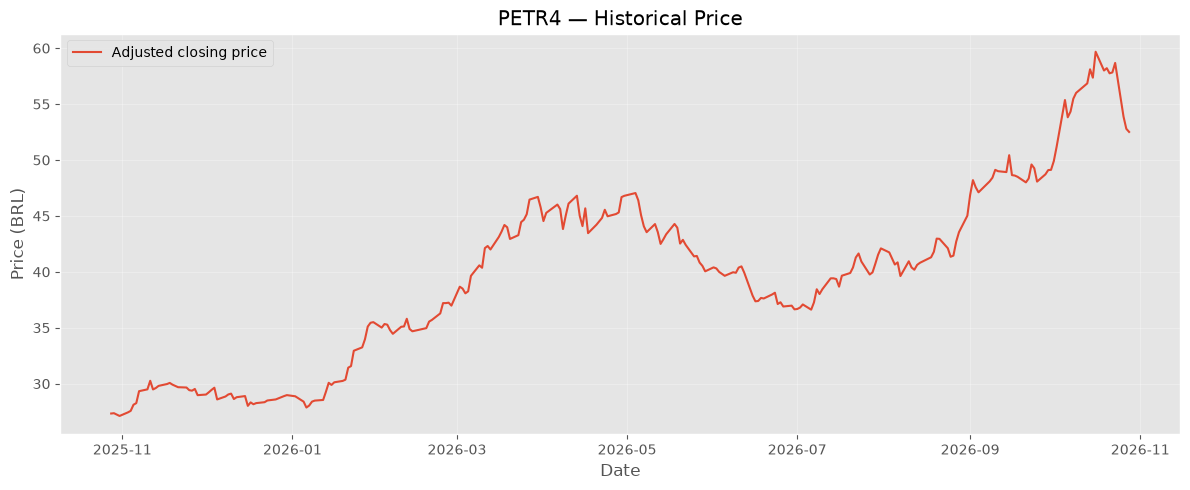

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["Close"],
    label="Adjusted closing price",
    linewidth=1.5
)

ax.set_title("PETR4 — Historical Price")
ax.set_xlabel("Date")
ax.set_ylabel("Price (BRL)")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "stock-performance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

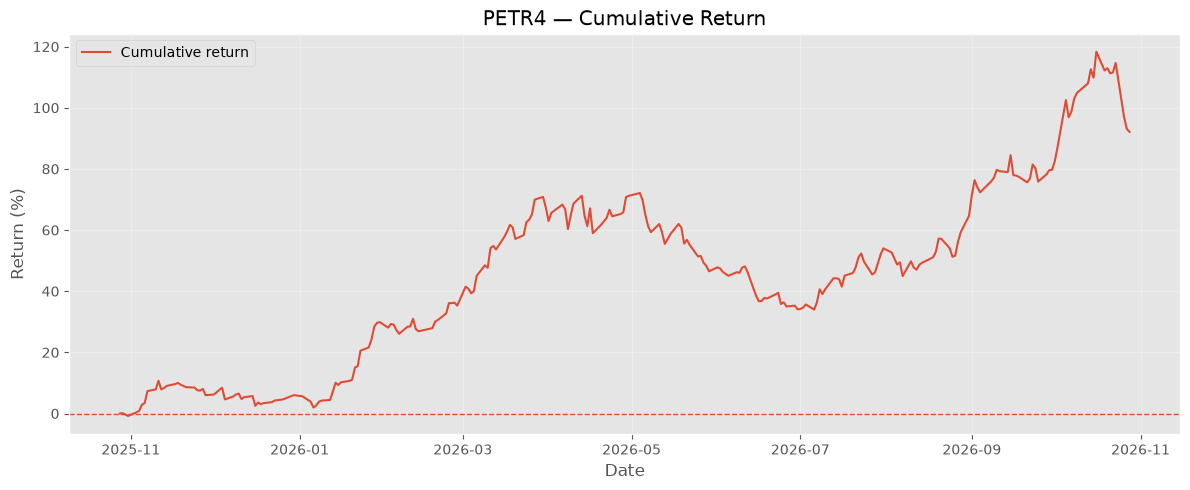

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["Cumulative_Return"] * 100,
    label="Cumulative return",
    linewidth=1.5
)

ax.axhline(0, linewidth=1, linestyle="--")

ax.set_title("PETR4 — Cumulative Return")
ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    IMAGES_DIR / "returns-comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()